# 02. 상품이 실제로 싸졌나 — 품목 구성, 품목 내 단가, 환율

미국 기록의 kg당 단가는 정책 후 해상 −16.9%, 항공 −36.0% 떨어졌다. 이것이 **상품이 싸진 것**인지 확인하려면 세 질문을 차례로 답해야 한다.

| 질문 | 방법 | 답 |
|---|---|---|
| 1. 싼 품목으로 옮겨 간 것인가, 같은 품목이 싸졌나 (M2) | 미국 HS10 기준 구성(mix)·품목 내 단가(price)·상호작용 분해 | 하락의 78~87%가 **같은 품목 안**에서 일어났다 |
| 2. 그중 환율 몫은 얼마인가 (사전 등록 Q3) | Δlog(USD/kg) = Δlog(원/kg) − Δlog(원/달러) 항등식 | 원화 약세는 하락의 **10~23%만** 설명한다 |
| 3. 같은 흐름을 한국은 어떻게 기록했나 (사전 등록 Q4) | 한국 수출 기록을 HSK10·HS6으로 분해 | 한국 기록의 kg당 금액은 **+8.0%**, 그것도 비싼 품목으로의 구성 이동이다 |

**결론**: 미국 기록의 단가 하락은 환율과 품목 구성으로 설명되지 않고, 같은 흐름의 한국 기록과 방향이 반대다. "상품이 싸졌다"보다 "미국 측 기록 가격이 달라졌다"에 가깝다(04 노트북).

비교 창은 정책 전후 같은 계절의 12개월(2024.09~2025.08 vs 2025.09~2026.08), 모든 단가는 **12개월 합계 금액 / 12개월 합계 중량**이다.
04 노트북의 월별 검정 수치(월별 평균의 전후 차이)와는 기준이 달라 숫자가 조금 다르다. 세목 단위의 분류 차이는 부록에 둔다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kbeauty import decompose, report, warehouse
from kbeauty.paths import POST_WINDOW, PRE_WINDOW, TABLES_DIR
from kbeauty.viz import annotations as an
from kbeauty.viz import notebook as nbviz
from kbeauty.viz.theme import COLORS as C

%matplotlib inline
nbviz.setup()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
fct = warehouse.load("fct_imports_hs10_mode_monthly"); fct["month"] = pd.to_datetime(fct["month"])
kr = warehouse.load("stg_kcs__kr_exports_us"); kr["month"] = pd.to_datetime(kr["month"])
names = warehouse.load("stg_kcs__hsk10_names").set_index("hsk10")["name_ko"]
summary = warehouse.load("mart_monthly_summary"); summary["month"] = pd.to_datetime(summary["month"])
krw = warehouse.load("stg_fed_board__fx_monthly").query("currency == 'KRW'")
krw = krw.assign(month=pd.to_datetime(krw["month"])).set_index("month")["lcu_per_usd"]
in_window = lambda d, w: d[d["month"].between(*w)]
print("US HS10 lines:", fct.hs10.nunique(), "| Korean HSK10 lines:", kr.hsk10.nunique())

US HS10 lines: 22 | Korean HSK10 lines: 32


## 1. 미국 기록 (M2): 하락은 품목 안에서 일어났다

In [2]:
us_mode = decompose.decompose_by_mode(fct, PRE_WINDOW, POST_WINDOW).set_index("mode")
sea_air = fct[fct["mode"] != "other"].groupby(["month", "hs10"], as_index=False)[["value_usd", "weight_kg"]].sum()
us_mode.loc["sea+air"] = pd.Series(decompose.window_decomposition(sea_air, "hs10", "value_usd", "weight_kg", PRE_WINDOW, POST_WINDOW))
us_mode[["uv_base", "uv_comp", "change", "change_pct", "mix", "price", "interaction", "mix_share_of_change", "price_share_of_change"]]

,uv_base,uv_comp,change,change_pct,mix,price,interaction,mix_share_of_change,price_share_of_change
mode,,,,,,,,,
vessel,19.809,16.455,-3.354,-0.169,-0.691,-2.617,-0.047,0.206,0.780
air,43.342,27.740,-15.602,-0.360,-0.114,-13.559,-1.929,0.007,0.869
sea+air,22.387,17.987,-4.400,-0.197,-0.789,-3.567,-0.044,0.179,0.811


**발견**: 미국 기록 기준 kg당 단가는 해상 19.81 → 16.46달러(−16.9%), 항공 43.34 → 27.74달러(−36.0%), 해상+항공 22.39 → 17.99달러(−19.7%)다.
하락분의 78~87%가 **같은 HS10 품목 안의 단가 하락**이고, 싼 품목으로의 구성 이동은 18% 안팎이다.
미국 기록만 보면 "K-뷰티 제품 자체가 kg당 더 싸게 들어오고 있다"로 읽힌다. 다음 두 절에서 이 해석을 환율과 한국 기록으로 점검한다.

## 2. 환율 (Q3): 원화 약세가 달러 단가를 얼마나 끌어내렸나

수출업체가 원화 가격을 그대로 두어도, 원화가 약해지면 달러로 환산한 단가는 내려간다. 12개월 합계 기준으로
달러 단가 변화를 '원화 단가 변화'와 '금액 가중 평균 환율 변화'로 정확히 나눈다.

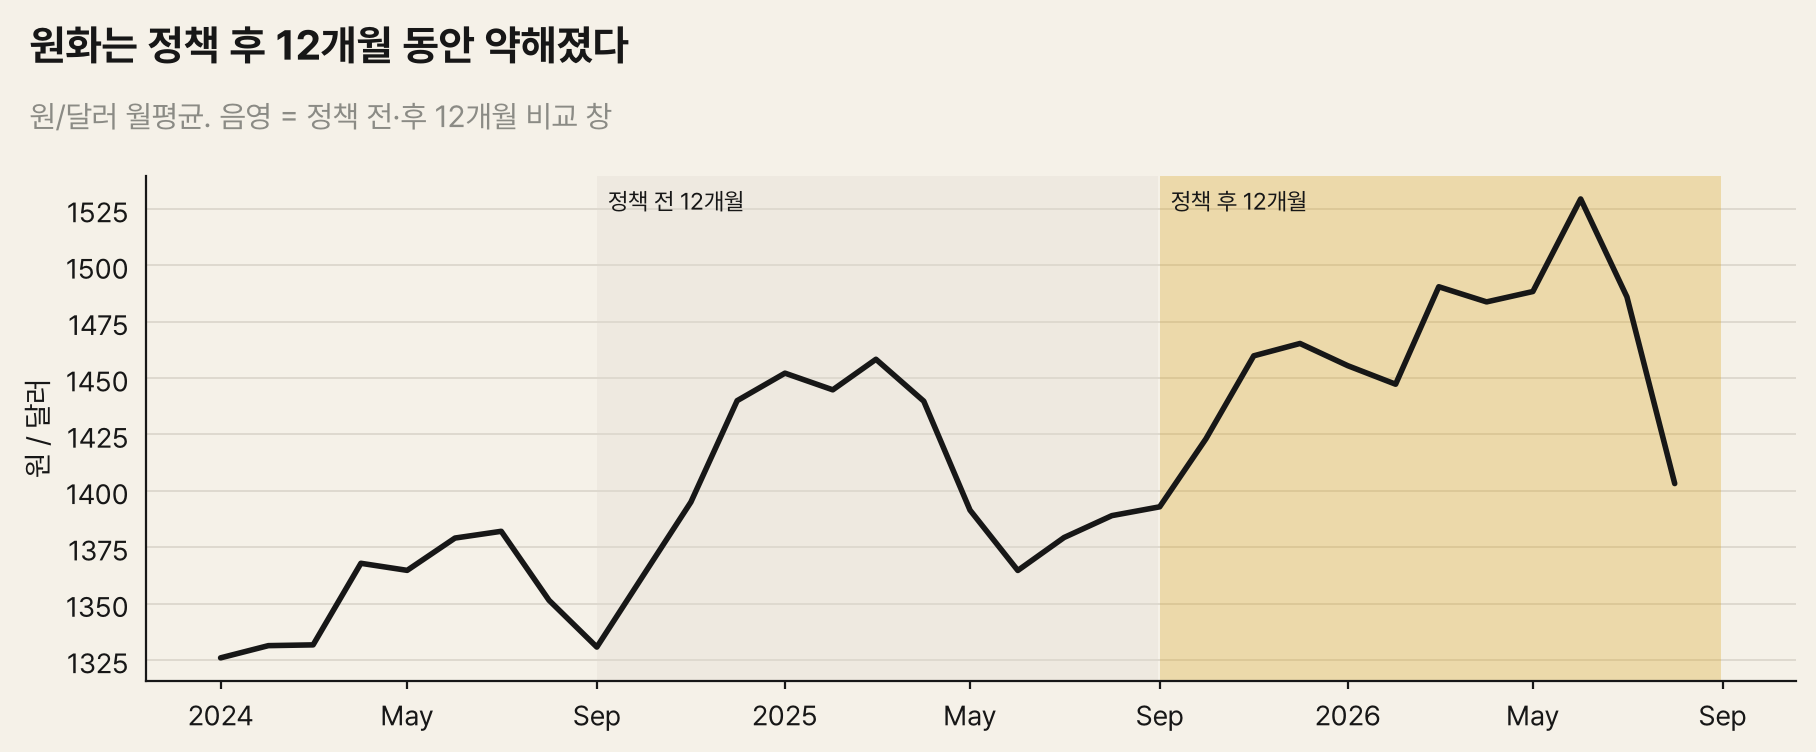

,usd_per_kg_pre,usd_per_kg_post,rate_pre,rate_post,dlog_usd_per_kg,dlog_lcu_per_kg,dlog_rate,fx_share_of_change
series,,,,,,,,
"US imports, vessel",19.809,16.455,"1,400.194","1,460.531",-0.185,-0.143,0.042,0.227
"US imports, air",43.342,27.740,"1,398.536","1,462.739",-0.446,-0.401,0.045,0.101
"US imports, sea+air",22.387,17.987,"1,399.842","1,460.993",-0.219,-0.176,0.043,0.195
Korean exports (FOB),19.064,20.581,"1,401.132","1,462.875",0.077,0.120,0.043,-0.563


In [3]:
fig, ax = nbviz.figure(title="원화는 정책 후 12개월 동안 약해졌다", subtitle="원/달러 월평균. 음영 = 정책 전·후 12개월 비교 창")
k = krw.loc["2024-01-01":"2026-08-01"]
for (a, b), c, name in ((PRE_WINDOW, C["grid"], "정책 전 12개월"), (POST_WINDOW, C["primary"], "정책 후 12개월")):
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.offsets.MonthEnd(0), color=c, alpha=0.3, lw=0)
    an.note(ax, pd.Timestamp(a), 1.0, name, coords=("data", "axes fraction"), va="top", xytext=(4, -4))
ax.plot(k.index, k, color=C["ink"], lw=2)
ax.set_ylabel("원 / 달러")
plt.show()
fx_tbl = pd.read_csv(TABLES_DIR / "fx_decomposition.csv").set_index("series")
fx_tbl[["usd_per_kg_pre", "usd_per_kg_post", "rate_pre", "rate_post", "dlog_usd_per_kg", "dlog_lcu_per_kg", "dlog_rate", "fx_share_of_change"]]

아래 셀은 위 표(`run_all` 결과)를 노트북에서 다시 계산해 같은지 확인한다.

In [4]:
ss = summary.set_index("month")
check = decompose.fx_decomposition(ss.air_value_usd, ss.air_weight_kg, krw.reindex(ss.index), PRE_WINDOW, POST_WINDOW)
assert np.isclose(check["dlog_usd_per_kg"], fx_tbl.loc["US imports, air", "dlog_usd_per_kg"])
assert np.isclose(check["dlog_usd_per_kg"], check["dlog_lcu_per_kg"] - check["dlog_rate"])  # identity
print("identity holds; matches reports/tables/fx_decomposition.csv")

identity holds; matches reports/tables/fx_decomposition.csv


**발견 (사전 등록 Q3)**: 정책 후 12개월 금액 가중 평균 환율은 1,400원 → 1,461원으로 원화가 약 4.3% 약해졌다(Δlog 0.043).

| 구분 | 달러 단가 변화 (Δlog) | 원화 단가 변화 | 환율 몫 |
|---|---|---|---|
| 미국 수입, 해상 | −0.185 | −0.143 | 23% |
| 미국 수입, 항공 | −0.446 | −0.401 | 10% |
| 미국 수입, 해상+항공 | −0.219 | −0.176 | 20% |
| 한국 수출(FOB) | **+0.077** | **+0.120** | (반대 방향) |

**판단**:
- 원화 약세는 미국 측 달러 단가 하락의 **10~23%만** 설명한다. 원화로 환산해도 미국 측 단가는 해상 −14%, 항공 −40%(로그) 떨어졌다.
- 한국 측 기록은 달러 기준으로도 올랐고, 원화 기준으로는 더 크게 올랐다.
- 따라서 미국 측 단가 하락의 대부분은 **환율로 설명되지 않는다.**

## 3. 한국 기록 (Q4): 같은 흐름을 한국은 어떻게 기록했나

한국 관세청 기록은 HSK 10단위로 미국보다 일부 더 세밀하다(예: 미국 3304.99 한 세목 ↔ 한국 4개 세목).
한국 측 kg당 금액 변화를 세목 단위로 분해하고, 같은 방법을 HS6 단위와 미국 측에도 적용해 비교한다.

In [5]:
gran = pd.read_csv(TABLES_DIR / "granularity_decomposition.csv").set_index("series")
gran[["uv_base", "uv_comp", "change", "change_pct", "mix", "price", "interaction", "mix_share_of_change", "price_share_of_change"]]

,uv_base,uv_comp,change,change_pct,mix,price,interaction,mix_share_of_change,price_share_of_change
series,,,,,,,,,
"Korea, HSK10",19.064,20.581,1.517,0.080,2.085,0.305,-0.872,1.374,0.201
"Korea, HS6",19.064,20.581,1.517,0.080,1.876,0.192,-0.551,1.236,0.126
"US, HS10 (sea+air)",22.387,17.987,-4.400,-0.197,-0.789,-3.567,-0.044,0.179,0.811
"US, HS6 (sea+air)",22.387,17.987,-4.400,-0.197,-0.716,-3.600,-0.085,0.163,0.818


In [6]:
def item_table(df, item, value, weight):
    p0 = in_window(df, PRE_WINDOW).groupby(item)[[value, weight]].sum()
    p1 = in_window(df, POST_WINDOW).groupby(item)[[value, weight]].sum()
    t = pd.DataFrame({"kg_share_pre": p0[weight] / p0[weight].sum(), "kg_share_post": p1[weight] / p1[weight].sum(),
                      "usd_per_kg_pre": p0[value] / p0[weight], "usd_per_kg_post": p1[value] / p1[weight],
                      "value_post_musd": p1[value] / 1e6})
    t["share_change_pp"] = (t.kg_share_post - t.kg_share_pre) * 100
    t["mix_contribution"] = (t.kg_share_post - t.kg_share_pre) * t.usd_per_kg_pre
    return t.sort_values("value_post_musd", ascending=False)

kr_items = item_table(kr, "hsk10", "export_usd", "export_kg")
kr_items.insert(0, "name_ko", names.reindex(kr_items.index).values)
kr_items.head(12)

,name_ko,kg_share_pre,kg_share_post,usd_per_kg_pre,usd_per_kg_post,value_post_musd,share_change_pp,mix_contribution
hsk10,,,,,,,,
3304991000,기초화장용 제품류,0.297,0.301,27.946,27.205,"1,051.318",0.366,0.102
3304999000,기타,0.147,0.230,28.297,25.605,755.117,8.267,2.339
3307909000,기타,0.291,0.202,3.032,6.337,164.689,-8.898,-0.270
3304109000,기타,0.028,0.019,52.108,57.858,137.500,-0.975,-0.508
3304992000,메이크업용 제품류,0.025,0.023,39.106,42.348,127.536,-0.120,-0.047
3307904000,마스크 팩,0.080,0.069,13.766,13.567,120.810,-1.053,-0.145
3305909000,기타,0.048,0.048,11.938,13.268,81.907,0.053,0.006
3305100000,샴푸,0.028,0.050,9.082,7.007,44.707,2.216,0.201
3304209000,기타,0.005,0.005,83.011,62.774,42.177,0.027,0.023


**발견 (사전 등록 Q4)**: 한국 기록의 kg당 금액은 19.06 → 20.58달러(**+8.0%**, 12개월 합계 기준)로 올랐다. 분해하면 정반대 이야기다.

| 기록 | 단가 변화 | 구성 효과 | 품목 내 단가 | 상호작용 |
|---|---|---|---|---|
| 한국, HSK10 | +1.52 | **+2.08** | +0.30 | −0.87 |
| 한국, HS6 | +1.52 | +1.88 | +0.19 | −0.55 |
| 미국, HS10 (해상+항공) | −4.40 | −0.79 | **−3.57** | −0.04 |
| 미국, HS6 (해상+항공) | −4.40 | −0.72 | −3.60 | −0.09 |

- 한국 측 상승은 **구성 이동**이 만들었다. 3304.99-9000(기타 미용 조제품, kg당 약 26~28달러)의 중량 비중이 14.7% → 23.0%로 늘고,
  kg당 3달러대의 3307.90-9000(기타) 비중이 29.1% → 20.2%로 줄었다. 품목 자체의 단가는 거의 그대로다(품목 내 효과 +0.30, 약 +1.6%).
- 세분할수록 구성 효과가 조금 커진다(한국 HS6 1.88 → HSK10 2.08). 사전 등록 질문의 답은 "**그렇다, 다만 차이는 작다**"이다.
- 미국 측은 같은 기간 구성은 오히려 싼 쪽으로 약간 움직였고(−0.79), 하락 대부분이 품목 내 단가(−3.57)에서 나왔다.

**같은 흐름을 두 나라가 정반대로 기록했다.** 한국은 "더 비싼 품목을 더 많이 보냈다", 미국은 "같은 품목이 더 싸게 들어왔다".

## 결론

| 질문 | 답 | 근거의 강도 |
|---|---|---|
| M2: 미국 기록의 단가 하락은 무엇인가 | 해상 −17%, 항공 −36%. 대부분(78~87%)이 **HS10 품목 안의 하락** | 강함(항등식 분해) |
| Q3: 환율 몫은 | 원화 약세(4.3%)가 미국 측 하락의 **10~23%만** 설명. 원화 기준으로도 크게 하락 | 강함(항등식) |
| Q4: 세분하면 구성 효과가 커지나 | 한국 기록에서는 **그렇다**(HS6 1.88 → HSK10 2.08, 차이는 작음). 한국 측 단가 상승(+8%)은 대부분 구성 이동 | 강함(항등식) |
| 두 나라 기록의 관계 | 한국: "더 비싼 품목을 더 보냈다"(구성 +, 품목 내 ≈ 0). 미국: "같은 품목이 더 싸게 들어왔다"(품목 내 −16%) | 중간: 세번 분류 차이(마스크 팩 등)가 섞여 있으나 그것만으로는 설명되지 않음 |

### 이 결과가 더한 것
1. 04 노트북의 결론(미국 측 신고 단가가 한국 측보다 낮아짐)을 **환율과 품목 구성으로는 설명할 수 없다**는 점을 확인했다.
   환율은 10~23%만 설명하고, 한국 측에서는 품목 내 단가가 거의 변하지 않았다.
2. 미국 측 '품목 내 단가 하락'은 상품 가격보다 **미국 측 과세가격 기록의 변화**일 가능성이 더 커졌다(가설, 통관 단위 자료 필요).
3. 두 나라의 세번 분류가 다르다(마스크 팩). 세목 단위 비교는 이 점을 감안해야 한다.

### 한계
- 한국 수출 통계에는 운송수단 구분이 없어, 한국 측 분해는 운송수단 전체 기준이다.
- 마스크 팩의 미국 측 분류는 추정이다.
- 12개월 합계 기준 수치는 04 노트북의 월별 검정 수치(월별 평균의 전후 차이)와 기준이 달라 조금 다르다(예: 한국 kg당 금액 +8% vs +12%).

---

## 부록: 두 나라 세목의 분류 차이와 일치 확인

### A1. 3304.99 안쪽: 미국이 한 세목으로 묶은 것을 한국은 넷으로 나눈다

In [7]:
sub = kr_items.loc[kr_items.index.str.startswith("330499")]
sub[["name_ko", "kg_share_pre", "kg_share_post", "usd_per_kg_pre", "usd_per_kg_post", "value_post_musd", "mix_contribution"]]

,name_ko,kg_share_pre,kg_share_post,usd_per_kg_pre,usd_per_kg_post,value_post_musd,mix_contribution
hsk10,,,,,,,
3304991000,기초화장용 제품류,0.297,0.301,27.946,27.205,"1,051.318",0.102
3304999000,기타,0.147,0.230,28.297,25.605,755.117,2.339
3304992000,메이크업용 제품류,0.025,0.023,39.106,42.348,127.536,-0.047
3304993000,어린이용 제품류,0.000,0.000,28.613,25.102,0.074,-0.009


**발견**: 미국이 한 세목(3304995000)으로 묶은 3304.99를 한국은 넷으로 나눈다.
- **기초화장용 제품류(3304.99-1000)**: 중량 비중 29.7% → 30.1%로 안정적이고, kg당 27.9 → 27.2달러(−2.6%)로 거의 그대로다. 정책 후 12개월 수출 10.5억 달러로 가장 크다.
- **기타(3304.99-9000)**: 비중이 8.3%p 늘어 구성 효과의 대부분(+2.34)을 만들었다. 정책 후 7.6억 달러다.
- **메이크업용 제품류(3304.99-2000)**: kg당 39.1 → 42.3달러로 올랐다.
- **어린이용 제품류(3304.99-3000)**: 금액이 매우 작다(7만 달러).

미국 기록으로는 이 안쪽의 움직임을 볼 수 없다. 미국 측 '품목 내 단가 하락'에는 실제 가격 변화와 함께 이런 세목 간 이동이 섞여 있을 수 있다.
그러나 한국 측에서 기초화장용의 단가가 거의 변하지 않은 것을 보면, 세목 이동만으로 미국 측의 −16% 품목 내 하락을 설명하기는 어렵다.

### A2. 마스크 팩은 어디로 갔나

한국 HSK에는 '마스크 팩'(3307.90-4000) 세목이 따로 있다. 04 노트북에서 330790(기타 화장품 조제품)은 미국 기록이 한국의 34%에 불과했다.
마스크 팩을 미국이 다른 세번(예: 3304.99)으로 분류한다면 HS6 단위 비교와 구성 분해가 모두 영향을 받는다.

In [8]:
mask = kr[kr.hsk10 == "3307904000"].set_index("month")[["export_usd", "export_kg"]]
k_3307 = kr[kr.hs6 == "330790"].groupby("month")["export_usd"].sum()
us_by_hs6 = fct[fct["mode"] != "other"].assign(hs6=lambda d: d.hs10.str[:6]).groupby(["month", "hs6"])["value_usd"].sum().unstack()
mask_tbl = pd.DataFrame({
    "KR 마스크 팩 (3307.90-4000)": [in_window(kr.query("hsk10 == '3307904000'"), w).export_usd.sum() / 1e6 for w in (PRE_WINDOW, POST_WINDOW)],
    "KR 330790 전체": [in_window(kr.query("hs6 == '330790'"), w).export_usd.sum() / 1e6 for w in (PRE_WINDOW, POST_WINDOW)],
    "US 330790 (해상+항공)": [us_by_hs6.loc[w[0]:w[1], "330790"].sum() / 1e6 for w in (PRE_WINDOW, POST_WINDOW)],
    "KR 330499 전체": [in_window(kr.query("hs6 == '330499'"), w).export_usd.sum() / 1e6 for w in (PRE_WINDOW, POST_WINDOW)],
    "US 330499 (해상+항공)": [us_by_hs6.loc[w[0]:w[1], "330499"].sum() / 1e6 for w in (PRE_WINDOW, POST_WINDOW)],
}, index=["정책 전 12개월 (백만 달러)", "정책 후 12개월 (백만 달러)"]).T
mask_tbl["mask_share_of_kr_330790"] = np.nan
mask_tbl.loc["KR 마스크 팩 (3307.90-4000)", "mask_share_of_kr_330790"] = (mask_tbl.iloc[0, 1] / mask_tbl.iloc[1, 1])
mask_tbl

,정책 전 12개월 (백만 달러),정책 후 12개월 (백만 달러),mask_share_of_kr_330790
KR 마스크 팩 (3307.90-4000),114.297,120.810,0.423
KR 330790 전체,207.595,285.715,NaN
US 330790 (해상+항공),77.585,91.175,NaN
KR 330499 전체,"1,396.931","1,934.045",NaN
US 330499 (해상+항공),"1,399.855","1,611.965",NaN


**발견**: 한국의 마스크 팩 수출(3307.90-4000)은 정책 전 12개월 1.14억 달러, 정책 후 1.21억 달러다. 정책 후 기준 한국 330790 전체의 42%를 차지한다.
그런데 **미국 기록의 330790 전체가 정책 전 0.78억 달러로, 한국의 마스크 팩 하나보다 작다.**
반대로 330499는 정책 전 두 나라 기록이 거의 같았다(한국 13.97억, 미국 14.00억 달러).

**판단**: 미국은 한국산 마스크 팩의 상당 부분을 330790이 아닌 다른 세번(3304.99로 추정)으로 분류하는 것으로 보인다.
이것은 추정이며, 미국 측 품목 분류 결정(CBP 분류 사례) 확인이 필요하다. 영향은 두 가지다.
1. HS6 단위의 미러 비교(04 노트북 부록 A2)에는 교차 분류가 섞여 있어, 세목별 비율보다 **전체 합계 비율**이 믿을 만하다. 04 노트북에서 전체 합계를 주 지표로 쓴 근거다.
2. 미국 330499의 단가에는 kg당 13~14달러인 마스크 팩이 섞여 있을 수 있다. 마스크 팩 비중이 늘면 미국 측 '품목 내 단가'가 낮아 보이는 효과가 생긴다.
   다만 한국 측에서 마스크 팩 비중은 오히려 줄었다(8.0% → 6.9%). 이 효과로 미국 측 하락을 설명하기도 어렵다.

### A3. 일치 확인

미국 측 운송수단별 분해가 `scripts/run_all.py`의 표(`reports/tables/unit_value_decomposition.csv`)와 같은지 확인한다.

In [9]:
saved = pd.read_csv(TABLES_DIR / "unit_value_decomposition.csv").set_index("mode")
for mode in ("vessel", "air"):
    for col in ("mix", "price", "interaction"):
        assert np.isclose(saved.loc[mode, col], us_mode.loc[mode, col], atol=1e-12)
print("notebook decomposition matches reports/tables/unit_value_decomposition.csv")

notebook decomposition matches reports/tables/unit_value_decomposition.csv
